In [40]:
import polars as pl
import numpy as np
import sys
sys.path.append("/kaggle/input/models/fedorfesenko/metrcs/other/default/1")
from metrics import evaluate_candidates

from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt

from collections import defaultdict
from typing import List, Dict
import pickle
import json
from pathlib import Path


In [2]:
df_train = pl.read_parquet("/kaggle/input/datasets/fedorfesenko/train-interactions/df_interactions_train.parquet")
df_val = pl.read_parquet("/kaggle/input/datasets/fedorfesenko/train-interactions/df_interactions_val.parquet")

In [3]:
TOP_K_SIMILAR = 100


In [4]:
cart_train = (
    df_train.filter(pl.col("action_type") == "AT_CartUpdate")
    .select(["user_id", "product_id"])
    .unique()
)

cart_val = (
    df_val
    .filter(pl.col("action_type") == "AT_CartUpdate")
    .select(["user_id", "product_id"])
    .unique()
)

print(f"Cart в train: {cart_train.height:,}")
print(f"Cart в val:   {cart_val.height:,}")

Cart в train: 132,226
Cart в val:   4,602


In [5]:
user_ids = cart_train["user_id"].unique().to_list()
item_ids = cart_train["product_id"].unique().to_list()

In [6]:
user_to_idx = {u: i for i, u in enumerate(user_ids)}
item_to_idx = {u: i for i, u in enumerate(item_ids)}

idx_to_item = {v: k for k, v in item_to_idx.items()}

n_users = len(user_ids)
n_items = len(item_ids)

print(f"Users: {n_users:,}")
print(f"Items: {n_items:,}")

Users: 2,211
Items: 13,106


In [7]:
cart_train.sort("user_id")

user_id,product_id
u64,u64
2849249366679451,14568677726886356869
2849249366679451,6458244614391609220
2849249366679451,17634529010307879940
2849249366679451,10735954070739046368
2849249366679451,2567221131262973750
…,…
18436895732283272638,8160408648746551177
18436895732283272638,12614743690798922474
18436895732283272638,11854514036573606390


In [8]:
# по строкам - users
# по столбцам - items

rows = [user_to_idx[u] for u in cart_train["user_id"].to_list()]
cols = [item_to_idx[i] for i in cart_train["product_id"].to_list()]

data = np.ones(len(rows), dtype=np.float32)

X = csr_matrix((data, (rows, cols)), shape=(n_users, n_items))

In [9]:
print(f"X shape: {X.shape}")
print(f"Non-zero: {X.nnz:,}")
print(f"Всего ячеек: {X.shape[0] * X.shape[1]:,}")
print(f"Нулей: {X.shape[0] * X.shape[1] - X.nnz:,}")
print(f"Density: {X.nnz / (X.shape[0] * X.shape[1]):.6f}")
print(f"Memory: {X.data.nbytes / 1e6:.2f} MB")

X shape: (2211, 13106)
Non-zero: 132,226
Всего ячеек: 28,977,366
Нулей: 28,845,140
Density: 0.004563
Memory: 0.53 MB


In [10]:
X[14, 23]

np.float32(0.0)

In [11]:
X_norm = normalize(X, norm='l2', axis=0)
co_sim = X_norm.T @ X_norm


print(f"X_norm shape:   {X_norm.shape}")
print(f"co_sim shape:   {co_sim.shape}")
print(f"co_sim non-zero: {co_sim.nnz:,}")
print(f"co_sim memory:  {co_sim.data.nbytes / 1e6:.2f} MB")

X_norm shape:   (2211, 13106)
co_sim shape:   (13106, 13106)
co_sim non-zero: 20,410,224
co_sim memory:  81.64 MB


In [12]:
co_sim_no_diag = co_sim.copy()
co_sim_no_diag.setdiag(0)
print(f"Max вне диагонали: {co_sim_no_diag.max():.4f}")
print(f"Min вне диагонали: {co_sim_no_diag.min():.4f}")
print(f"Средняя близость: {co_sim_no_diag.data.mean():.4f}")

Max вне диагонали: 1.0000
Min вне диагонали: 0.0000
Средняя близость: 0.1172


In [13]:
similar_items = {}

In [14]:
co_sim_csr = co_sim.tocsr()

In [15]:
for item_idx in range(n_items):
    row = co_sim_csr[item_idx]
    indices = row.indices
    values = row.data

    mask = indices != item_idx # пропускаем самого себя
    indices = indices[mask]
    values = values[mask]

    if len(values) > TOP_K_SIMILAR:
        top_k_local = np.argpartition(-values, TOP_K_SIMILAR)[:TOP_K_SIMILAR]
    else:
        top_k_local = np.arange(len(values))

    
    top_k_scores = values[top_k_local]
    sorted_order = np.argsort(-top_k_scores)
    top_k_local = top_k_local[sorted_order]

    top_k_indices = indices[top_k_local]
    top_k_scores = values[top_k_local]

    similar_items[item_idx] = list(zip(top_k_indices.tolist(), top_k_scores.tolist()))

In [16]:
# Item 4
sample_idx = 4
print(f"\nItem {sample_idx} (id={idx_to_item[sample_idx]}):")
for neighbor_idx, score in similar_items[sample_idx][:10]:
    print(f"  {neighbor_idx} (id={idx_to_item[neighbor_idx]}): {score:.4f}")


Item 4 (id=2178680975736970):
  3603 (id=5080045227909958707): 0.2872
  4589 (id=6466157451763572912): 0.2801
  5633 (id=7952969901743467054): 0.2722
  11923 (id=16783219239438527777): 0.2722
  4046 (id=5750964587954056603): 0.2722
  434 (id=637163340718037727): 0.2722
  7022 (id=9926383464461599403): 0.2722
  10113 (id=14243919221481625811): 0.2722
  10968 (id=15429279571033157404): 0.2642
  6218 (id=8770736119490606705): 0.2611


In [17]:
def build_item2item_candidates(
    user_history: Dict[int, List[int]],      # {user_id: [item_id, ...]}
    similar_items: Dict[int, List[tuple]],   # {item_idx: [(neighbor_idx, score), ...]}
    item_to_idx: Dict[int, int],
    idx_to_item: Dict[int, int],
    top_k: int = 500,
) -> Dict[int, List[int]]:
    """
    Для каждого пользователя — top-K кандидатов через Item2Item
    """
    candidates = {}
    
    for user_id, history in user_history.items():
        scores = defaultdict(float)
        
        for item_id in history:
            if item_id not in item_to_idx:
                continue
            
            item_idx = item_to_idx[item_id]
            
            for neighbor_idx, sim_score in similar_items.get(item_idx, []):
                neighbor_item = idx_to_item[neighbor_idx]
                scores[neighbor_item] += sim_score
        
        # Сортируем по score (убывание)
        sorted_items = sorted(scores.items(), key=lambda x: -x[1])
        candidates[user_id] = [item for item, _ in sorted_items[:top_k]]
    
    return candidates

In [18]:
user_history_train = (
    cart_train
    .group_by("user_id")
    .agg(pl.col("product_id").alias("items"))
)

user_history_train_dict = {
    row["user_id"]: row["items"]
    for row in user_history_train.iter_rows(named=True)
}
len(user_history_train_dict)

2211

In [19]:
user_history_val = (
    cart_val
    .group_by("user_id")
    .agg(pl.col("product_id").alias("items"))
)
user_history_val_dict = {
    row["user_id"]: row["items"]
    for row in user_history_val.iter_rows(named=True)
}
len(user_history_val_dict)

432

In [20]:
predicted_candidates  = build_item2item_candidates(
    user_history=user_history_train_dict,
    similar_items=similar_items,
    item_to_idx=item_to_idx,
    idx_to_item=idx_to_item,
    top_k=500
)

In [21]:
len(predicted_candidates)

2211

In [22]:
# истинные кандидаты для val
true_items_val = {
    user_id: set(items)
    for user_id, items in user_history_val_dict.items()
}

In [23]:
result = evaluate_candidates(
    predicted_candidates,
    true_items_val,
    k=500,
    total_items=n_items,
)
result

{'recall@500': 0.4017882149531111,
 'hit_rate@500': 0.8291457286432161,
 'mrr@500': 0.08930992590532925,
 'coverage': 0.9481916679383489,
 'n_requests': 398,
 'avg_candidates': 487.2638190954774}

Метрика не совсем честно посчитана, потому что, если посмотреть на n_requests: 398, то становится понятно, что ряд пользователей не получили предсказания, и не дали вклад в метрику

Поэтому для тех пользователей, кому мы не можем дать предсказания (потому что у него нет истории, или она слишком короткая) мы даем топ-500 популярных товаров

In [24]:
pop = (
    df_train
    .filter(pl.col("action_type") == "AT_CartUpdate")
    .group_by(pl.col("product_id"))
    .agg(pl.len().alias("n_carts"))
    .sort(by="n_carts", descending=True)
)

In [25]:
pop_items = pop.head(500)["product_id"].to_list()

In [26]:
cold_count = 0
for user_id in true_items_val.keys():
    if user_id not in predicted_candidates or len(predicted_candidates[user_id]) == 0:
        predicted_candidates[user_id] = pop_items
        cold_count += 1

print(f"Cold users (fallback): {cold_count}")
print(f"Total users: {len(predicted_candidates)}")

Cold users (fallback): 34
Total users: 2245


In [27]:
result2 = evaluate_candidates(
    predicted_candidates,
    true_items_val,
    k=500,
    total_items=n_items,
)

result2

{'recall@500': 0.396052557456425,
 'hit_rate@500': 0.8287037037037037,
 'mrr@500': 0.08985525158813638,
 'coverage': 0.9487257744544484,
 'n_requests': 432,
 'avg_candidates': 488.2662037037037}

 До этого мы все делали с нормированной матрицей X_norm, попробуем с сырой X

## Эксперементы с сырой X

In [28]:
co_sim_raw = X.T @ X

In [29]:
TOP_K_SIMILAR = 100
similar_items_raw = {}
co_sim_raw_csr = co_sim_raw.tocsr()

for item_idx in range(n_items):
    row = co_sim_raw_csr[item_idx]
    indices = row.indices
    values = row.data
    
    mask = indices != item_idx
    indices = indices[mask]
    values = values[mask]
    
    if len(values) > TOP_K_SIMILAR:
        top_k_local = np.argpartition(-values, TOP_K_SIMILAR)[:TOP_K_SIMILAR]
    else:
        top_k_local = np.arange(len(values))
    
    top_k_scores = values[top_k_local]
    sorted_order = np.argsort(-top_k_scores)
    top_k_local = top_k_local[sorted_order]
    
    top_k_indices = indices[top_k_local]
    top_k_scores = values[top_k_local]
    
    similar_items_raw[item_idx] = list(zip(top_k_indices.tolist(), top_k_scores.tolist()))

print(f"similar_items_raw: {len(similar_items_raw)} items")

similar_items_raw: 13106 items


In [30]:
predicted_raw = build_item2item_candidates(
    user_history=user_history_train_dict,
    similar_items=similar_items_raw,
    item_to_idx=item_to_idx,
    idx_to_item=idx_to_item,
    top_k=500,
)

In [31]:
# также как раньше добавляем популярные для cold-start
for user_id in true_items_val.keys():
    if user_id not in predicted_raw or len(predicted_raw[user_id]) == 0:
        predicted_raw[user_id] = pop_items

In [32]:
result_raw = evaluate_candidates(
    predicted_raw,
    true_items_val,
    k=500,
    total_items=n_items,
)

In [33]:
result_raw

{'recall@500': 0.45526619617374253,
 'hit_rate@500': 0.8518518518518519,
 'mrr@500': 0.09079712426904603,
 'coverage': 0.3699832137952083,
 'n_requests': 432,
 'avg_candidates': 481.712962962963}

Видим, что recall@k вырос, однако мы сильно потеряли в coverage

## Сравниваем

In [34]:
results = [
    {"model": "Item2Item_cosine", "k": 500, **result},
    {"model": "Item2Item_raw", "k": 500, **result_raw},
]

df_results = pl.DataFrame(results)

df_results

model,k,recall@500,hit_rate@500,mrr@500,coverage,n_requests,avg_candidates
str,i64,f64,f64,f64,f64,i64,f64
"""Item2Item_cosine""",500,0.401788,0.829146,0.08931,0.948192,398,487.263819
"""Item2Item_raw""",500,0.455266,0.851852,0.090797,0.369983,432,481.712963


Видим: модель без нормализации лучше по recall@k, но сильно проигрывает по coverage, попробуем понять значима ли разница в полноте

## Делаем бутстреп

In [35]:
def bootstrap_metric(
    df_metric: pl.DataFrame,     # с колонками user_id/request_id и metric_value
    metric_col: str,
    n_bootstrap: int = 1000,
    seed: int = 42,
) -> np.ndarray:
    """
    Bootstrap для одной метрики
    """
    np.random.seed(seed)
    
    values = df_metric[metric_col].to_numpy()
    n = len(values)
    
    bootstrap_scores = []
    
    for _ in range(n_bootstrap):
        # Resample с возвращением
        indices = np.random.choice(n, size=n, replace=True)
        sample = values[indices]
        bootstrap_scores.append(np.mean(sample))
    
    return np.array(bootstrap_scores)

In [36]:
from metrics import recall_at_k

def compute_per_user_metrics(
    predicted_candidates: dict,
    true_items: dict,
    k: int = 500,
) -> pl.DataFrame:
    """
    Считает метрику для каждого пользователя.
    """
    rows = []
    for user_id, candidates in predicted_candidates.items():
        if user_id not in true_items:
            continue
        trues = list(true_items[user_id])
        if len(trues) == 0:
            continue
        
        recall = recall_at_k(candidates[:k], trues, k)
        rows.append({"user_id": user_id, "recall": recall})
    
    return pl.DataFrame(rows)

# Per-user метрики для raw и cosine
df_raw = compute_per_user_metrics(predicted_raw, true_items_val)
df_cos = compute_per_user_metrics(predicted_candidates, true_items_val)

print(f"df_raw: {df_raw.shape}")
print(f"df_cos: {df_cos.shape}")

df_raw: (432, 2)
df_cos: (432, 2)


In [37]:
# Bootstrap
boot_raw = bootstrap_metric(df_raw, "recall", n_bootstrap=1000)
boot_cos = bootstrap_metric(df_cos, "recall", n_bootstrap=1000)

# 95% CI для каждой модели
ci_raw = np.percentile(boot_raw, [2.5, 97.5])
ci_cos = np.percentile(boot_cos, [2.5, 97.5])

print(f"Raw:  recall = {df_raw['recall'].mean():.4f}, 95% CI = [{ci_raw[0]:.4f}, {ci_raw[1]:.4f}]")
print(f"Cos:  recall = {df_cos['recall'].mean():.4f}, 95% CI = [{ci_cos[0]:.4f}, {ci_cos[1]:.4f}]")

Raw:  recall = 0.4553, 95% CI = [0.4278, 0.4831]
Cos:  recall = 0.3961, 95% CI = [0.3710, 0.4225]


In [38]:
def bootstrap_difference(
    df_a: pl.DataFrame,
    df_b: pl.DataFrame,
    metric_col: str = "recall",
    id_col: str = "user_id",
    n_bootstrap: int = 1000,
    seed: int = 42,
) -> dict:
    """
    Bootstrap разницы между двумя моделями
    """
    np.random.seed(seed)
    
    # Merge по user_id
    df_merged = df_a.join(df_b, on=id_col, how="inner", suffix="_b")
    
    values_a = df_merged[f"{metric_col}"].to_numpy()
    values_b = df_merged[f"{metric_col}_b"].to_numpy()
    
    n = len(values_a)
    
    diffs = []
    for _ in range(n_bootstrap):
        indices = np.random.choice(n, size=n, replace=True)
        diff = np.mean(values_a[indices]) - np.mean(values_b[indices])
        diffs.append(diff)
    
    diffs = np.array(diffs)
    ci = np.percentile(diffs, [2.5, 97.5])
    
    return {
        "mean_diff": float(np.mean(diffs)),
        "ci_lower": float(ci[0]),
        "ci_upper": float(ci[1]),
        "significant": bool(ci[0] > 0 or ci[1] < 0),  # 0 не в CI
        "diffs": diffs,
    }

# разницы
diff_result = bootstrap_difference(df_raw, df_cos, "recall")
print(f"\nРазница (raw - cosine):")
print(f"  Mean: {diff_result['mean_diff']:.4f}")
print(f"  95% CI: [{diff_result['ci_lower']:.4f}, {diff_result['ci_upper']:.4f}]")
print(f"  Значимо: {diff_result['significant']}")


Разница (raw - cosine):
  Mean: 0.0587
  95% CI: [0.0348, 0.0842]
  Значимо: True


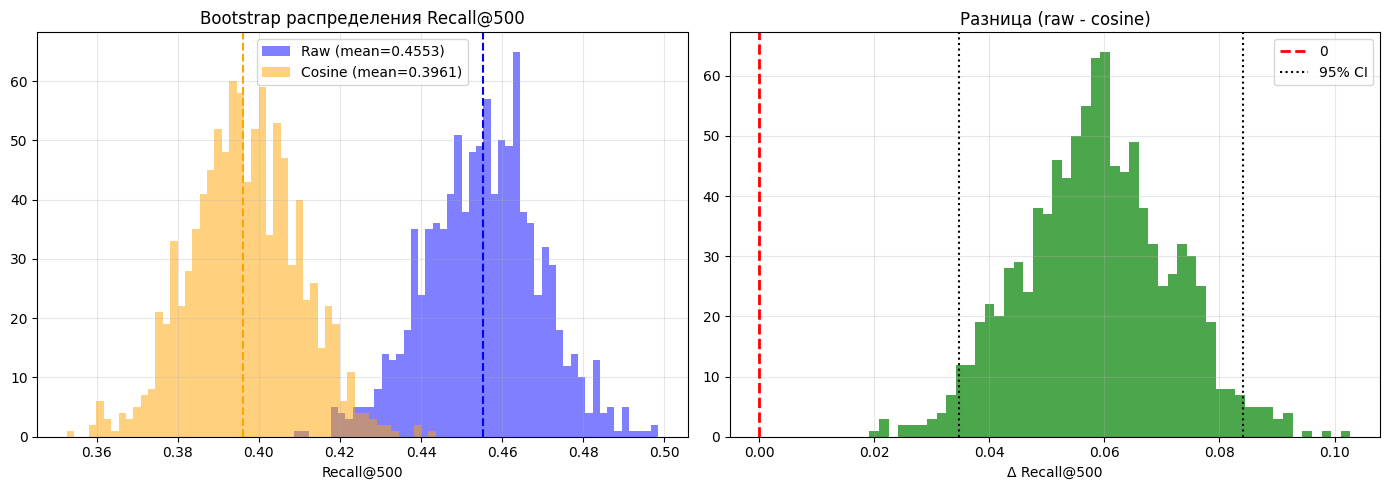

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.hist(boot_raw, bins=50, alpha=0.5, label=f"Raw (mean={df_raw['recall'].mean():.4f})", color="blue")
ax.hist(boot_cos, bins=50, alpha=0.5, label=f"Cosine (mean={df_cos['recall'].mean():.4f})", color="orange")
ax.axvline(df_raw["recall"].mean(), color="blue", linestyle="--")
ax.axvline(df_cos["recall"].mean(), color="orange", linestyle="--")
ax.set_title("Bootstrap распределения Recall@500")
ax.set_xlabel("Recall@500")
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
ax.hist(diff_result["diffs"], bins=50, color="green", alpha=0.7)
ax.axvline(0, color="red", linestyle="--", linewidth=2, label="0")
ax.axvline(diff_result["ci_lower"], color="black", linestyle=":", label="95% CI")
ax.axvline(diff_result["ci_upper"], color="black", linestyle=":")
ax.set_title("Разница (raw - cosine)")
ax.set_xlabel("Δ Recall@500")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Видим, что разница стат значима - все ок

## Сохраняем модель

In [41]:
Path("/kaggle/working/artifacts").mkdir(parents=True, exist_ok=True)

artifacts_i2i = {
    "similar_items": similar_items,         # dict {item_idx: [(neighbor_idx, score), ...]}
    "similar_items_raw": similar_items_raw, # dict — сырая версия
    
    "user_to_idx": user_to_idx,
    "item_to_idx": item_to_idx,
    "idx_to_item": idx_to_item,
    
    "n_users": n_users,
    "n_items": n_items,
    "TOP_K_SIMILAR": TOP_K_SIMILAR,
    
    "pop_items": pop_items,
}

with open("/kaggle/working/artifacts/i2i_artifacts.pkl", "wb") as f:
    pickle.dump(artifacts_i2i, f)

In [42]:
print(f" Сохранено: i2i_artifacts.pkl")
print(f"  similar_items: {len(similar_items)} items")
print(f"  similar_items_raw: {len(similar_items_raw)} items")
print(f"  user_to_idx: {len(user_to_idx)} users")
print(f"  item_to_idx: {len(item_to_idx)} items")
print(f"  pop_items: {len(pop_items)} items")

 Сохранено: i2i_artifacts.pkl
  similar_items: 13106 items
  similar_items_raw: 13106 items
  user_to_idx: 2211 users
  item_to_idx: 13106 items
  pop_items: 500 items
